In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from pathlib import Path
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
train_path = pd.read_csv('/kaggle/input/digit-recognizer/train.csv')
test_path = pd.read_csv('/kaggle/input/digit-recognizer/test.csv')

## **What is perceptron**

* The perceptron is the simplest model of an artificial neuron, introduced by Frank Rosenblatt in 1958.
* It takes multiple inputs, and assigns each one a weight
Inputs:  x1, x2, ..., xn  
Weights: w1, w2, ..., wn
* The perceptron computes the weighted sum z = Σ(wi * xi) + b where b is the bias.
* The result z is passed through an activation function
* The output is usually binary (0 or 1) if it is above a certain threshold, it takes the value 1



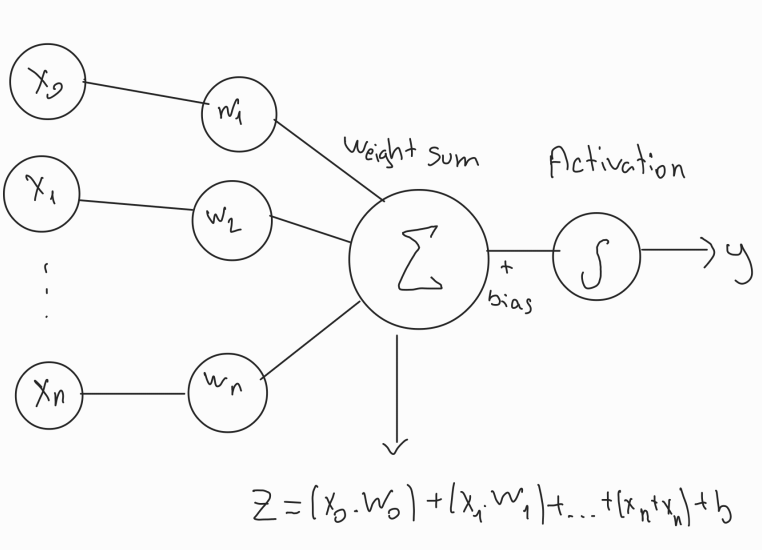

### Activation function

An activation function is a mathematical operation that shapes the output of a neuron in an artificial neural network.
In other words, it determines how active the neuron will be.

Put simply:
It takes the input values (for example, the weighted sum), processes them, and produces the final output.

sigmoid function maps any real-valued input from (−∞, +∞) into the interval (0,1).
σ(z)=1/(1+e^−z)

relu: if z< 0 z =  0 else z = z

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [ ]:
def relu(z):
    return np.maximum(0,z)

### AI Winter

in the 1960s, researchers discovered that perceptrons could only solve linearly separable problems (like AND, OR), but not more complex ones (like XOR).


-HIDDEN LAYERS

but the solution was actually quite simple instead of a single-layer perceptron, we stack multiple layers on top of each other. In other words, we add a hidden layer. This way, the network is no longer limited to drawing only straight lines; it can also learn curved and more complex decision boundaries. As a result, it becomes capable of solving more complicated problems like XOR.

So, the hidden layer gives artificial intelligence the ability to “think more deeply.” Think of a single-layer network as a very simple brain → it can only understand basic patterns. As you add more layers, the network can learn increasingly complex patterns.

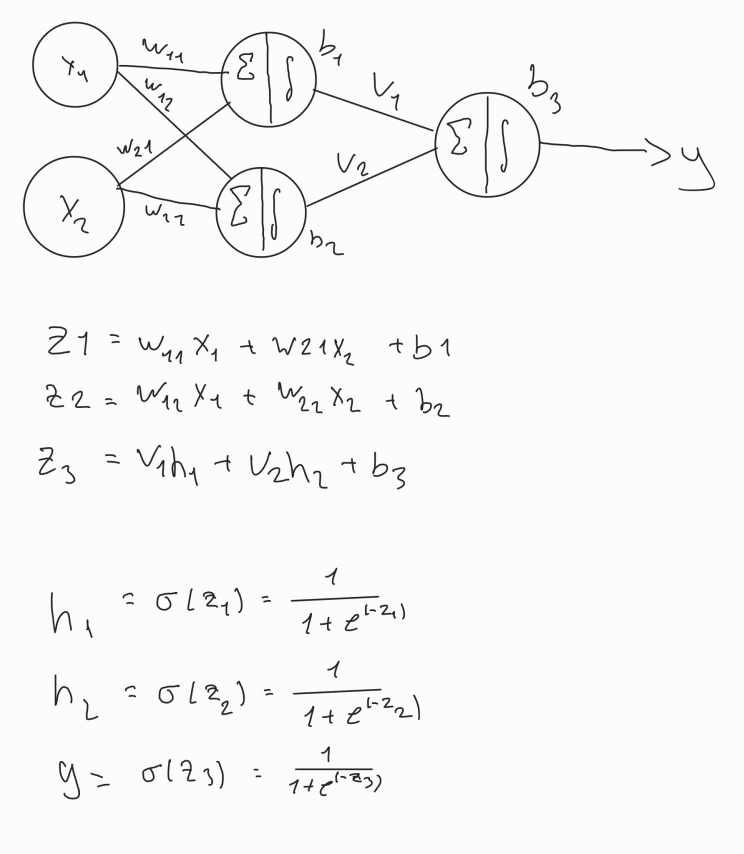

### Loss Function

A loss function measures the difference between the model’s predictions and the actual values.

It reduces errors to a single number and answers the question “how well are we doing” during training.

The goal is to minimize this value (e.g., using MSE).

In [ ]:
y_true = np.array([1, 0, 1, 1, 0])
y_pred = np.array([0.9, 0.2, 0.8, 0.4, 0.3])

mse = np.mean((y_true - y_pred) ** 2)

print("MSE:", mse)

### Backward pass

The main goal of the backward pass is to compute the gradient of the loss function 
L
L with respect to each parameter (weights and biases).
In other words, we want to find

∂L/∂wi, ∂L/∂bi

for all parameters in the network.

Once these gradients are calculated, we update the parameters using the Gradient Descent algorithm:

This iterative process allows the network to minimize the loss function and improve its predictions over time

## Backward pass - output delta

First, let’s calculate the output delta.
In other words, we compute the derivative of the loss function with respect to z3:

δ_output = ∂L / ∂z₃

But what does this tell us?
It represents the derivative of the output neuron with respect to its input (z3)the error signal.
The derivative is the slope of the function at that point, which tells us how much a small change in the parameters will affect the final output

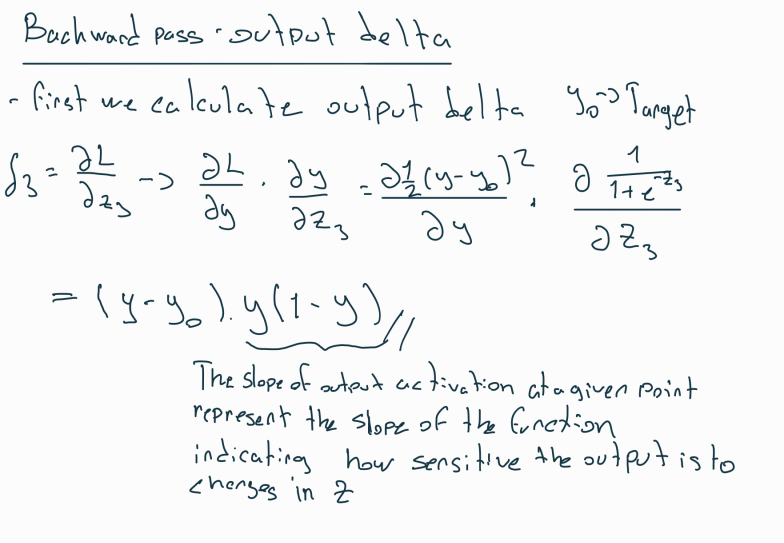

The error signal at the output neuron serves as the starting point for backpropagation.
It propagates backward through the hidden layers and drives the weight updates, enabling the entire network to learn

## What is Gradient

The gradient is the derivative of the loss function with respect to the weights.

shows how a specific weight influences the loss.

The gradient measures how sensitive the loss is to small changes in the weights.

It is a vector that points in the direction of the steepest ascent of the function.

To minimize the loss, we move in the opposite direction of the gradient (negative gradient).

***The gradient is a vector pointing toward the maximum value at the peak, and we multiply it by a negative value to move in that direction

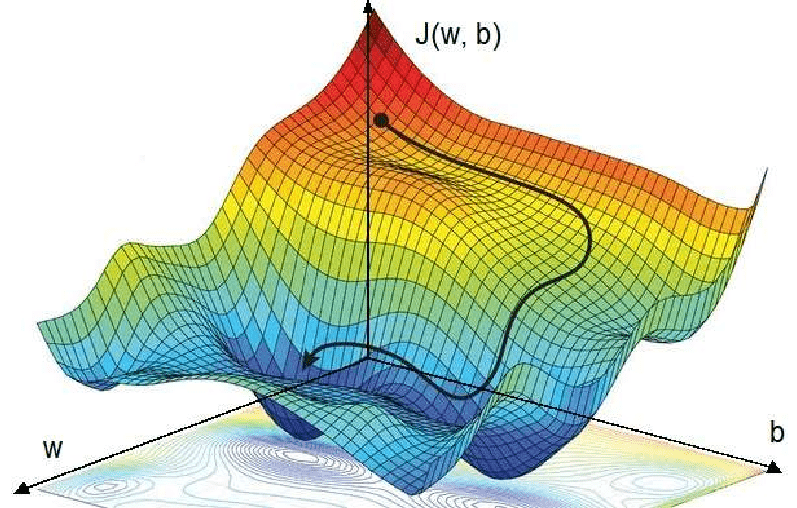

### Gradients of Hidden → Output Weights

At this stage, we use the output error signal (δoutput) to compute the gradients of the weights connecting the hidden layer to the output layer.

The gradient of a weight shows how much that weight influences the loss

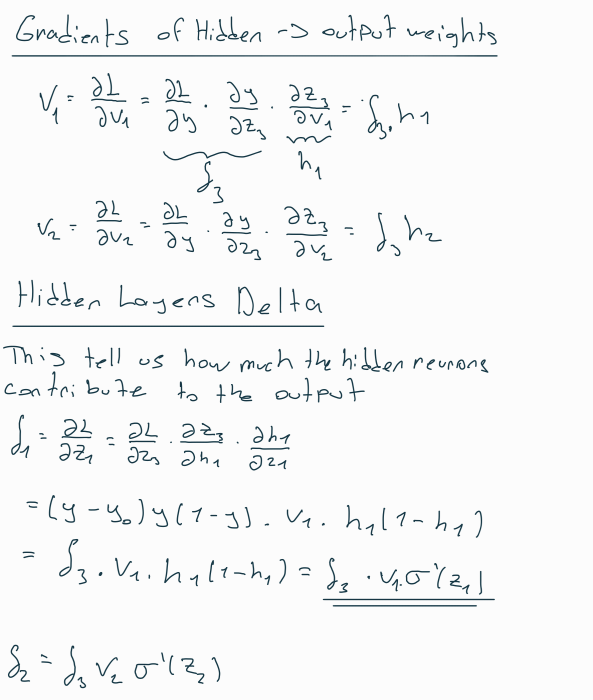

### Input -> Hidden Weights Gradients

At this stage, we compute the gradients of the weights connecting the input layer to the hidden layer

This expression tells us how much each input feature contributes to the error of the hidden neuron. In other words, it shows how small changes in the input values affect the loss function through the weights

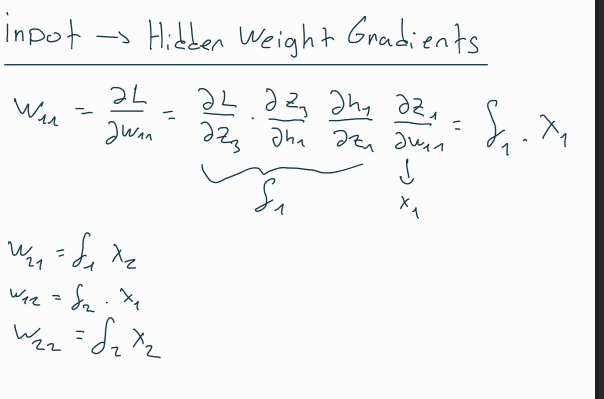

### Epoch, Learning rate, Early Stopping
epoach: an epoch is one complete pass through the entire training dataset

learning rate: The learning rate is a parameter that controls how big the steps are during gradient descent

early stopping: Early stopping is a technique used to prevent overfitting. During training, when the validation loss stops decreasing or starts increasing, training is stopped early. This way, the model is saved at its optimal point before it begins to overfit

## Gradients Descent

Gradient Descent is basically the heart of machine learning. The goal is simple: minimize the loss function. We do this by taking small steps downhill.

How does it work?

Imagine you’re standing on top of a mountain (high loss).

At each point, you can see an arrow showing the direction of the steepest slope. That arrow is the gradient.

But you want to reach the bottom (the minimum), so you walk in the opposite direction of the gradient.

The size of each step is controlled by the learning rate (η).

Too big → you overshoot and bounce around.

Too small → you crawl down super slowly.

And how many times do we do this? That’s where epochs come in.

One epoch = passing the entire training dataset once through the network and updating the weights.

Usually, training runs for many epochs.

But here’s the catch: if you train too long, the model starts memorizing instead of generalizing (overfitting).
That’s when early stopping saves the day.

During training, if the validation loss stops decreasing and starts increasing, we stop training early.

This keeps the model at its best point, without overfitting.

So in short: Gradient Descent = walking downhill. Learning rate = step size. Epoch = how many laps you make. Early stopping = knowing when to stop before messing things up.

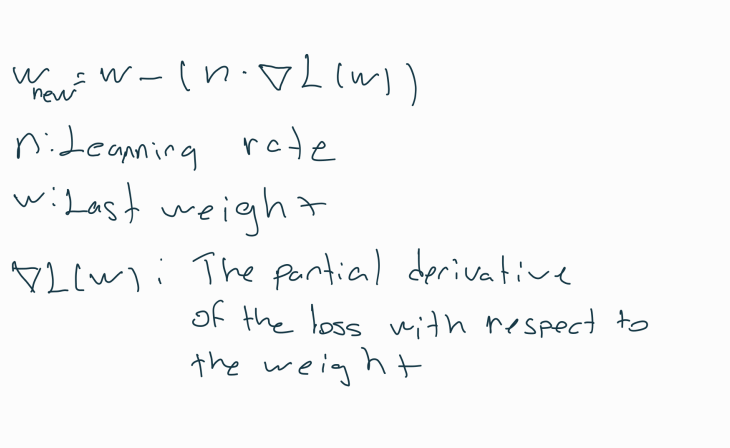

## ANN code

In [ ]:
# ACTIVATION FUNCTIONS
def sigmoid(x: np.ndarray)->np.ndarray:
    return 1/(1+ np.exp(-x))

def derivative_sigmoid(activated: np.ndarray)->np.ndarray:
    return activated * (1- activated)

def relu(x:np.ndarray)->np.ndarray:
    return np.maximum(0,x)

def relu_derivative(pre_activation:np.ndarray)->np.ndarray:
    
    derivative = np.zeros_like(pre_activation, dtype=np.float32)
    
    for i in range(pre_activation.shape[0]):
        for j in range(pre_activation.shape[1]):
            if pre_activation[i, j] > 0.0:
                derivative[i, j] = 1.0
            else:
                derivative[i, j] = 0.0

    return derivative

def softmax(x:np.ndarray)->np.ndarray:
    shifted = x - np.max(x, axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)



#SIDE FUNCTIONS

def cross_entropy(probs:np.ndarray, targets:np.ndarray)->float:
    eps = 1e-12
    return float(-np.sum(targets*np.log(probs+eps))/targets.shape[0])

def one_hot_encode(label:np.ndarray, num_classes:int=10)->np.ndarray:
    eye = np.eye(num_classes, dtype=np.float32)
    return eye[label]

def train_val_split(features, targets, val_fraction=0.1, seed=42):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(features.shape[0])
    val_size = int(features.shape[0] * val_fraction)
    val_idx = indices[:val_size]
    train_idx = indices[val_size:]
    return features[train_idx], targets[train_idx], features[val_idx], targets[val_idx]


def load_mnist_csv(path: Path, normalize: bool = True):
    dataset = np.loadtxt(path, delimiter=",", skiprows=1, dtype=np.float32)
    labels = dataset[:, 0].astype(np.int64)
    pixels = dataset[:, 1:]
    if normalize:
        pixels /= 255.0
    return pixels, labels

In [ ]:
class NeuralNetwork:
    def __init__(self, layer_sizes, activations, learning_rate=0.01, seed=None):
        self.learning_rate = learning_rate
        self.activations = [name.lower() for name in activations]
        rng = np.random.default_rng(seed)

        self.weights = []
        self.biases = []

        for idx in range(len(layer_sizes) - 1):
            in_dim = layer_sizes[idx]
            out_dim = layer_sizes[idx + 1]

            if idx < len(self.activations):
                act = self.activations[idx]
                if act == 'relu':
                    scale = np.sqrt(2.0 / in_dim)
                elif act == 'sigmoid':
                    scale = np.sqrt(1.0 / in_dim)
                else:
                    raise ValueError('ERROR')
            else:
                scale = np.sqrt(1.0 / in_dim)

            weight_matrix = rng.normal(0.0, scale, size=(in_dim, out_dim)).astype(np.float32)
            bias_vector = np.zeros((1, out_dim), dtype=np.float32)
            
            self.weights.append(weight_matrix)
            self.biases.append(bias_vector)

    def forward(self, inputs):
        activations = [inputs]
        pre_activations = []
        current = inputs

        for idx, (weight, bias) in enumerate(zip(self.weights, self.biases)):
            z = current @ weight + bias
            pre_activations.append(z)

            if idx < len(self.activations):
                activation_name = self.activations[idx]
                if activation_name == 'relu':
                    current = relu(z)
                elif activation_name == 'sigmoid':
                    current = sigmoid(z)
                else:
                    raise ValueError('ERROR: Unknown activation function')
            else:
                current = softmax(z)

            activations.append(current)

        return current, {'activations': activations, 'pre_activations': pre_activations}

    
    def backward(self, cache, targets):
        activations = cache['activations']
        pre_activations = cache['pre_activations']
        batch_size = targets.shape[0]

        grads_w = [np.zeros_like(w) for w in self.weights]
        grads_b = [np.zeros_like(b) for b in self.biases]

        delta = (activations[-1] - targets) / batch_size

        for layer in reversed(range(len(self.weights))):
            grads_w[layer] = activations[layer].T @ delta
            grads_b[layer] = np.sum(delta, axis=0, keepdims=True)

            if layer > 0:
                propagated = delta @ self.weights[layer].T
                activation_name = self.activations[layer - 1]
                if activation_name == 'relu':
                    delta = propagated * relu_derivative(pre_activations[layer - 1])
                else:
                    delta = propagated * derivative_sigmoid(activations[layer])

        return grads_w, grads_b



    def update_parameters(self, grads_w, grads_b):
        for idx in range(len(self.weights)):
            self.weights[idx] -= self.learning_rate*grads_w[idx]
            self.biases[idx] -= self.learning_rate * grads_b[idx]
            
    def predict(self, inputs):
        probs, _ = self.forward(inputs)
        return np.argmax(probs, axis=1)

    def compute_loss(self, inputs, targets):
        probs, _ = self.forward(inputs)
        return cross_entropy(probs, targets)

    
    def evaluate_accuracy(self, inputs, targets):
        predicted = self.predict(inputs)
        actual = np.argmax(targets,axis=1)
        return float(np.mean(predicted == actual))




    def train(self, inputs, targets, epochs=10, batch_size=128,
              validation_inputs=None, validation_targets=None):
        
        sample_count = inputs.shape[0]
        
        for epoch in range(1, epochs + 1):
            permutation = np.random.permutation(sample_count)
            inputs_shuffled = inputs[permutation]
            targets_shuffled = targets[permutation]
            epoch_loss = 0.0
            
            for start in range(0, sample_count, batch_size):
                end = start + batch_size
                batch_inputs = inputs_shuffled[start:end]
                batch_targets = targets_shuffled[start:end]
                probs, cache = self.forward(batch_inputs)
                batch_loss = cross_entropy(probs, batch_targets)
                epoch_loss += batch_loss * batch_inputs.shape[0]
                grads_w, grads_b = self.backward(cache, batch_targets)
                self.update_parameters(grads_w, grads_b)
                
            epoch_loss /= sample_count
            train_acc = self.evaluate_accuracy(inputs, targets)
            
            log_message = f"epoch {epoch:02d} | loss {epoch_loss:.4f} | acc {train_acc * 100:.2f}%"
            
            if validation_inputs is not None and validation_targets is not None:
                val_loss = self.compute_loss(validation_inputs, validation_targets)
                val_acc = self.evaluate_accuracy(validation_inputs, validation_targets)
                log_message += f" | val_loss {val_loss:.4f} | val_acc {val_acc * 100:.2f}%"
            print(log_message)

In [ ]:
from pathlib import Path
train_path = Path("/kaggle/input/digit-recognizer/train.csv")
test_path = Path("/kaggle/input/digit-recognizer/test.csv")

X_train, y_train = load_mnist_csv(train_path, normalize=True)
X_test, _ = load_mnist_csv(test_path, normalize=True)

In [ ]:
train_x, train_y, val_x, val_y = train_val_split(X_train, y_train, val_fraction=0.1, seed=42)

In [ ]:
layer_sizes = [train_x.shape[1], 128,64,32,10]
activations = ["relu", "relu",'relu'] 
network = NeuralNetwork(layer_sizes, activations, learning_rate=0.01, seed=42)

In [ ]:
train_y = one_hot_encode(train_y, num_classes=10)
val_y   = one_hot_encode(val_y, num_classes=10)

In [ ]:
network.train(
    inputs=train_x,
    targets=train_y,
    epochs=50,
    batch_size=128,
    validation_inputs=val_x,
    validation_targets=val_y,
)

In [ ]:
test_data = np.loadtxt(test_path, delimiter=",", skiprows=1, dtype=np.float32) / 255.0
predictions = network.predict(test_data)

## Submission

In [ ]:
submission = np.column_stack([np.arange(1, predictions.shape[0] + 1), predictions])
np.savetxt("submission.csv", submission, fmt="%d", delimiter=",", header="ImageId,Label", comments="")
print("submission.csv succesful!")

In [ ]:
ls

In [ ]:
# I will explain the code section in version 2.
# There may be some confusion, but I will fix that.